In [7]:
!pip install torchvision

In [9]:
import numpy as np
import torchvision
dataset = torchvision.datasets.EuroSAT(root='./data', download=True)

classes = dataset.classes
targets = np.array(dataset.targets)

print(f"Total de imagens: {len(dataset)}")
print(f"Número de classes: {len(classes)}\n")

import pandas as pd

df_classes = pd.DataFrame({
    'Classe': classes,
    'Quantidade': [np.sum(targets == i) for i in range(len(classes))]
})
df_classes['Proporção (%)'] = (df_classes['Quantidade'] / len(dataset) * 100).round(2)
display(df_classes)

Total de imagens: 27000
Número de classes: 10



,Classe,Quantidade,Proporção (%)
0,AnnualCrop,3000,11.11
1,Forest,3000,11.11
2,HerbaceousVegetation,3000,11.11
3,Highway,2500,9.26
4,Industrial,2500,9.26
5,Pasture,2000,7.41
6,PermanentCrop,2500,9.26
7,Residential,3000,11.11
8,River,2500,9.26
9,SeaLake,3000,11.11


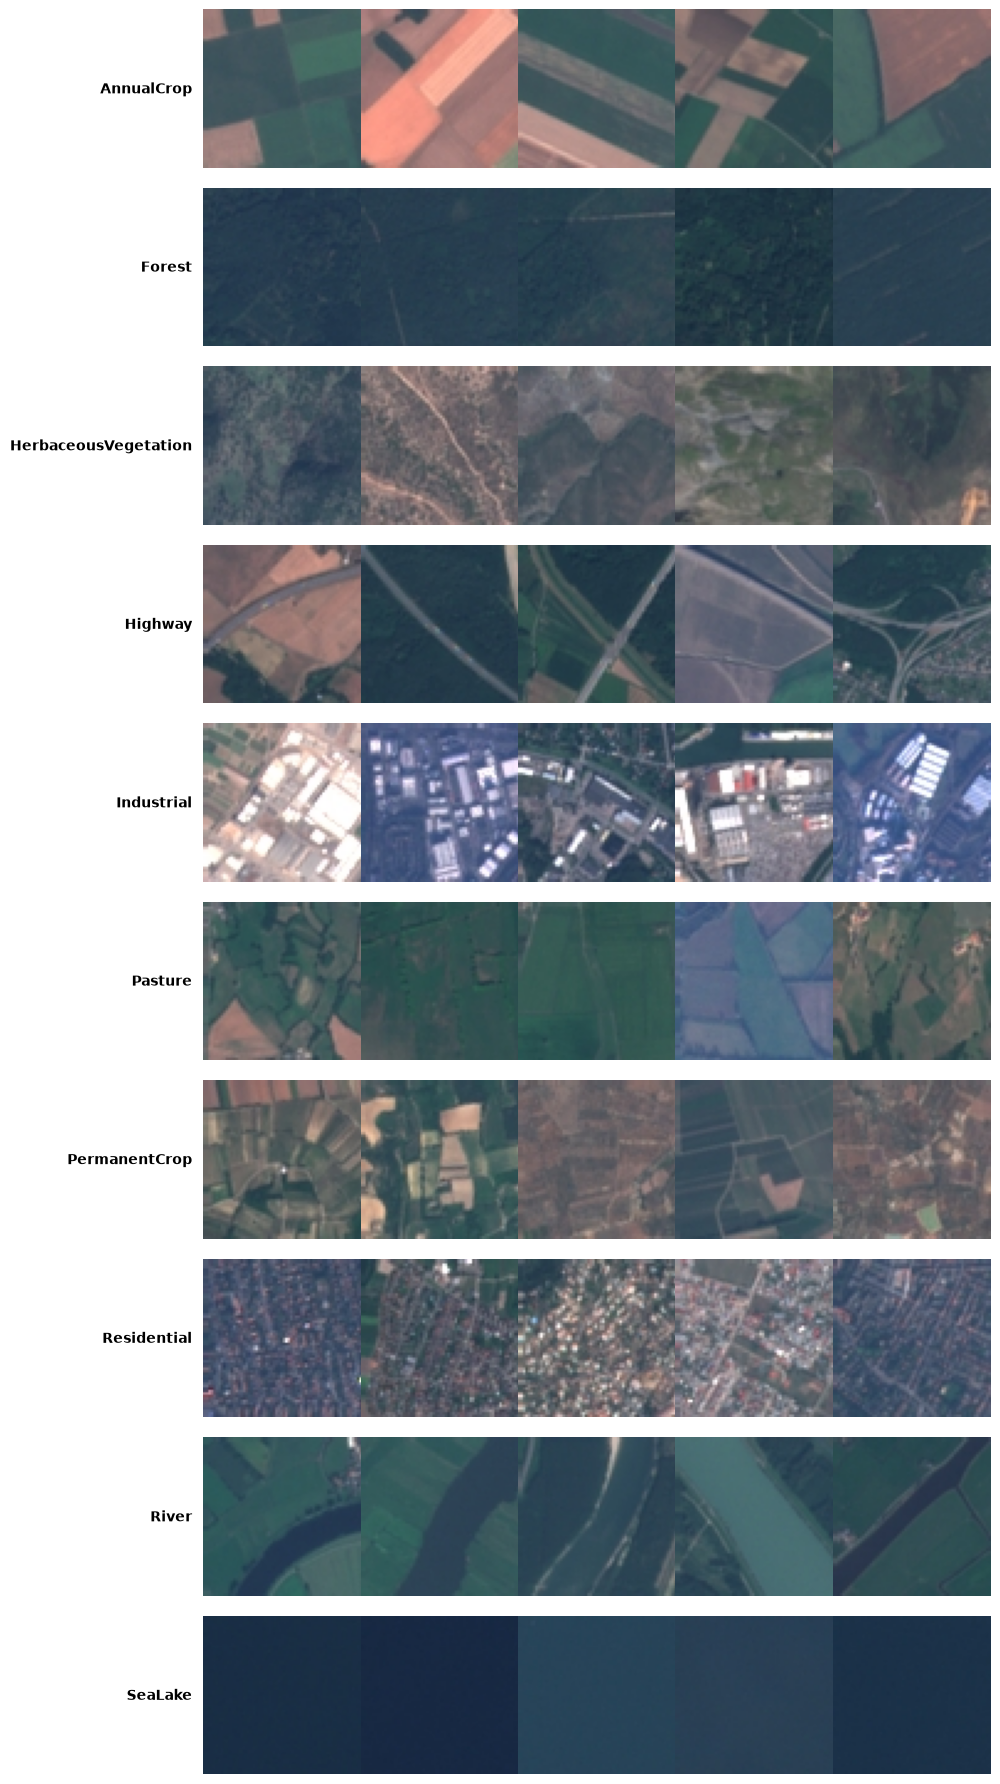

In [10]:
import matplotlib.pyplot as plt

np.random.seed(42)
fig, axes = plt.subplots(len(classes), 5, figsize=(10, 18))

for class_idx, class_name in enumerate(classes):
    idxs = np.random.choice(np.where(targets == class_idx)[0], size=5, replace=False)
    for col_idx, img_idx in enumerate(idxs):
        img, _ = dataset[img_idx]
        ax = axes[class_idx, col_idx]
        ax.imshow(img)
        ax.axis('off')
        if col_idx == 0:
            ax.text(-5, 32, class_name, fontsize=10, va='center', ha='right', fontweight='bold')

plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(dataset))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    stratify=targets,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=targets[temp_idx],
    random_state=42
)

In [12]:
import torch
from torchvision import transforms

to_tensor = transforms.ToTensor()  

train_imgs = torch.stack([to_tensor(dataset[i][0]) for i in train_idx]) 

mean_rgb = train_imgs.mean(dim=(0, 2, 3))
std_rgb = train_imgs.std(dim=(0, 2, 3))

In [13]:
from torch.utils.data import Dataset, DataLoader

class EuroSATSubset(Dataset):
    def __init__(self, base_dataset, indices, transform=None):
        self.base_dataset = base_dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        img, label = self.base_dataset[self.indices[idx]]
        if self.transform:
            img = self.transform(img)
        return img, label

norm_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_rgb.tolist(), std=std_rgb.tolist())
])

train_dataset = EuroSATSubset(dataset, train_idx, transform=norm_transform)
val_dataset   = EuroSATSubset(dataset, val_idx,   transform=norm_transform)
test_dataset  = EuroSATSubset(dataset, test_idx,  transform=norm_transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=64, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=64, shuffle=False)

In [14]:
import torch
import torch.nn as nn

features = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2)
)


In [15]:
classifier = nn.Sequential(
    nn.Flatten(),
    nn.Linear(128 * 8 * 8, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

In [16]:
class EuroSATCNN(nn.Module):
    def __init__(self, features, classifier):
        super().__init__()
        self.features = features
        self.classifier = classifier

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = EuroSATCNN(features, classifier).to(device)

In [17]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [18]:
epochs = 30
best_val_loss = float("inf")
best_epoch = 0
best_weights = None

train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(1, epochs + 1):
    model.train()
    train_loss, train_correct = 0.0, 0

    for X, y in train_loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(X)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(X)
        train_correct += (logits.argmax(dim=1) == y).sum().item()

    train_loss /= len(train_dataset)
    train_acc = train_correct / len(train_dataset)
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    model.eval()
    val_loss, val_correct = 0.0, 0

    with torch.no_grad():
        for X, y in val_loader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            val_loss += criterion(logits, y).item() * len(X)
            val_correct += (logits.argmax(dim=1) == y).sum().item()

    val_loss /= len(val_dataset)
    val_acc = val_correct / len(val_dataset)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    print(f"Epoch {epoch:2d}/{epochs} "
          f"| train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} "
          f"| val_loss: {val_loss:.4f} val_acc: {val_acc:.4f}")

print(f"\nMelhor época (menor val_loss): {best_epoch} (val_loss: {best_val_loss:.4f})")

Epoch  1/30 | train_loss: 0.9479 train_acc: 0.6533 | val_loss: 0.6723 val_acc: 0.7607
Epoch  2/30 | train_loss: 0.5563 train_acc: 0.7992 | val_loss: 0.5052 val_acc: 0.8168
Epoch  3/30 | train_loss: 0.4260 train_acc: 0.8507 | val_loss: 0.4412 val_acc: 0.8444
Epoch  4/30 | train_loss: 0.3369 train_acc: 0.8822 | val_loss: 0.4803 val_acc: 0.8395
Epoch  5/30 | train_loss: 0.2762 train_acc: 0.9041 | val_loss: 0.4941 val_acc: 0.8235
Epoch  6/30 | train_loss: 0.2108 train_acc: 0.9270 | val_loss: 0.4053 val_acc: 0.8649
Epoch  7/30 | train_loss: 0.1543 train_acc: 0.9450 | val_loss: 0.3945 val_acc: 0.8704
Epoch  8/30 | train_loss: 0.1289 train_acc: 0.9534 | val_loss: 0.4699 val_acc: 0.8644
Epoch  9/30 | train_loss: 0.1220 train_acc: 0.9579 | val_loss: 0.3513 val_acc: 0.8896
Epoch 10/30 | train_loss: 0.0737 train_acc: 0.9756 | val_loss: 0.4398 val_acc: 0.8837
Epoch 11/30 | train_loss: 0.0825 train_acc: 0.9727 | val_loss: 0.4601 val_acc: 0.8738
Epoch 12/30 | train_loss: 0.0717 train_acc: 0.9754 | v

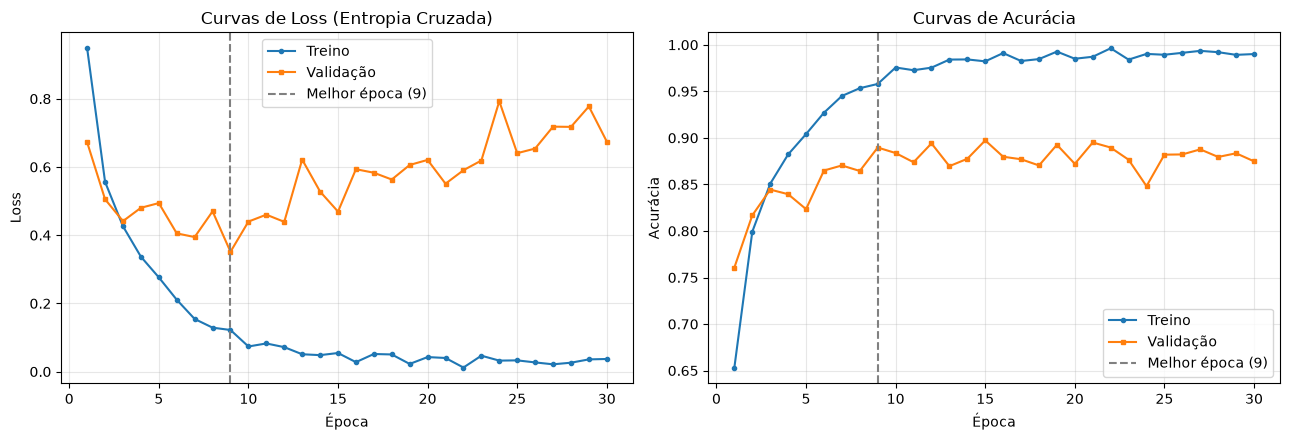

In [19]:
import matplotlib.pyplot as plt

epochs_range = range(1, epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range, train_losses, label="Treino", color="tab:blue", marker="o", markersize=3)
axes[0].plot(epochs_range, val_losses, label="Validação", color="tab:orange", marker="s", markersize=3)
axes[0].axvline(best_epoch, color="gray", linestyle="--", label=f"Melhor época ({best_epoch})")
axes[0].set_title("Curvas de Loss (Entropia Cruzada)")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, train_accs, label="Treino", color="tab:blue", marker="o", markersize=3)
axes[1].plot(epochs_range, val_accs, label="Validação", color="tab:orange", marker="s", markersize=3)
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"Melhor época ({best_epoch})")
axes[1].set_title("Curvas de Acurácia")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
import numpy as np

model.load_state_dict(best_weights)
model.eval()

y_true, y_pred = [], []

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)
        logits = model(X)
        preds = logits.argmax(dim=1).cpu().numpy()
        y_pred.extend(preds)
        y_true.extend(y.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [24]:
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, index=dataset.classes, columns=dataset.classes)
print(cm_df)

acc_global = accuracy_score(y_true, y_pred)
print(f"\nAcurácia Global no Teste: {acc_global:.4f} ({acc_global*100:.2f}%)\n")
print(classification_report(y_true, y_pred, target_names=dataset.classes, digits=4))

                      AnnualCrop  Forest  HerbaceousVegetation  Highway  \
AnnualCrop                   395       1                     5        5   
Forest                         0     434                     4        0   
HerbaceousVegetation          12       4                   379        8   
Highway                        6       0                     7      312   
Industrial                     0       0                     4       14   
Pasture                        6      14                    12        5   
PermanentCrop                 14       1                    37       12   
Residential                    0       0                     2        0   
River                          9       4                     8       22   
SeaLake                        2       0                     0        0   

                      Industrial  Pasture  PermanentCrop  Residential  River  \
AnnualCrop                     0        5             19            1     12   
Forest        

In [30]:
from torchvision import transforms
from torch.utils.data import DataLoader

# Recupera mean e std diretamente do transform já existente no val_dataset
norm_layer = [t for t in val_dataset.transform.transforms if isinstance(t, transforms.Normalize)][0]
mean, std = norm_layer.mean, norm_layer.std

# Transformação com Data Augmentation APENAS para o conjunto de treino
train_transform_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=180),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

train_dataset_aug = EuroSATSubset(
    val_dataset.base_dataset,
    train_dataset.indices,
    transform=train_transform_aug
)

train_loader_aug = DataLoader(train_dataset_aug, batch_size=64, shuffle=True)

features_aug = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2)
)

classifier_aug = nn.Sequential(
    nn.Flatten(),
    nn.Linear(128 * 8 * 8, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

model_aug = EuroSATCNN(features_aug, classifier_aug).to(device)
criterion_aug = nn.CrossEntropyLoss()
optimizer_aug = optim.Adam(model_aug.parameters(), lr=1e-3)

In [31]:
epochs_aug = 30
best_val_loss_aug = float("inf")
best_weights_aug = None
best_epoch_aug = 0

train_losses_aug, val_losses_aug, train_accs_aug, val_accs_aug = [], [], [], []

for epoch in range(1, epochs_aug + 1):
    model_aug.train()
    train_loss, train_correct = 0.0, 0
    for X, y in train_loader_aug:
        X, y = X.to(device), y.to(device)
        optimizer_aug.zero_grad()
        logits = model_aug(X)
        loss = criterion_aug(logits, y)
        loss.backward()
        optimizer_aug.step()
        train_loss += loss.item() * len(X)
        train_correct += (logits.argmax(dim=1) == y).sum().item()

    train_loss /= len(train_dataset_aug)
    train_acc = train_correct / len(train_dataset_aug)
    train_losses_aug.append(train_loss)
    train_accs_aug.append(train_acc)

    model_aug.eval()
    val_loss, val_correct = 0.0, 0
    with torch.no_grad():
        for X, y in val_loader:
            X, y = X.to(device), y.to(device)
            logits = model_aug(X)
            val_loss += criterion_aug(logits, y).item() * len(X)
            val_correct += (logits.argmax(dim=1) == y).sum().item()

    val_loss /= len(val_dataset)
    val_acc = val_correct / len(val_dataset)
    val_losses_aug.append(val_loss)
    val_accs_aug.append(val_acc)

    print(f"Epoch {epoch:2d}/{epochs_aug} | train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} | val_loss: {val_loss:.4f} val_acc: {val_acc:.4f}")

    if val_loss < best_val_loss_aug:
        best_val_loss_aug = val_loss
        best_weights_aug = {k: v.cpu().clone() for k, v in model_aug.state_dict().items()}
        best_epoch_aug = epoch

print(f"\nMelhor época com Data Augmentation (menor val_loss): {best_epoch_aug} (val_loss: {best_val_loss_aug:.4f})")

Epoch  1/30 | train_loss: 1.0613 train_acc: 0.6070 | val_loss: 0.7926 val_acc: 0.7074
Epoch  2/30 | train_loss: 0.6702 train_acc: 0.7546 | val_loss: 0.6986 val_acc: 0.7509
Epoch  3/30 | train_loss: 0.5682 train_acc: 0.7939 | val_loss: 0.6114 val_acc: 0.7854
Epoch  4/30 | train_loss: 0.4850 train_acc: 0.8265 | val_loss: 0.4342 val_acc: 0.8464
Epoch  5/30 | train_loss: 0.4268 train_acc: 0.8464 | val_loss: 0.3752 val_acc: 0.8684
Epoch  6/30 | train_loss: 0.3805 train_acc: 0.8653 | val_loss: 0.4111 val_acc: 0.8590
Epoch  7/30 | train_loss: 0.3568 train_acc: 0.8735 | val_loss: 0.3692 val_acc: 0.8704
Epoch  8/30 | train_loss: 0.3248 train_acc: 0.8859 | val_loss: 0.3226 val_acc: 0.8896
Epoch  9/30 | train_loss: 0.2977 train_acc: 0.8968 | val_loss: 0.4405 val_acc: 0.8575
Epoch 10/30 | train_loss: 0.2791 train_acc: 0.9016 | val_loss: 0.3193 val_acc: 0.8909
Epoch 11/30 | train_loss: 0.2593 train_acc: 0.9083 | val_loss: 0.2664 val_acc: 0.9104
Epoch 12/30 | train_loss: 0.2496 train_acc: 0.9141 | v

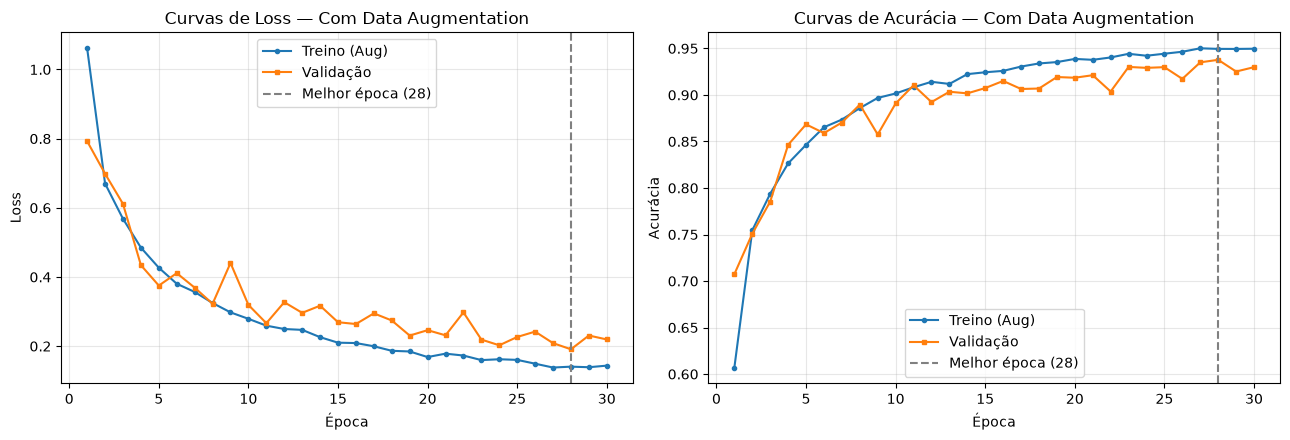

In [32]:
import matplotlib.pyplot as plt

epochs_range_aug = range(1, epochs_aug + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range_aug, train_losses_aug, label="Treino (Aug)", color="tab:blue", marker="o", markersize=3)
axes[0].plot(epochs_range_aug, val_losses_aug, label="Validação", color="tab:orange", marker="s", markersize=3)
axes[0].axvline(best_epoch_aug, color="gray", linestyle="--", label=f"Melhor época ({best_epoch_aug})")
axes[0].set_title("Curvas de Loss — Com Data Augmentation")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range_aug, train_accs_aug, label="Treino (Aug)", color="tab:blue", marker="o", markersize=3)
axes[1].plot(epochs_range_aug, val_accs_aug, label="Validação", color="tab:orange", marker="s", markersize=3)
axes[1].axvline(best_epoch_aug, color="gray", linestyle="--", label=f"Melhor época ({best_epoch_aug})")
axes[1].set_title("Curvas de Acurácia — Com Data Augmentation")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

model_aug.load_state_dict(best_weights_aug)
model_aug.eval()

y_true_aug, y_pred_aug = [], []

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)
        logits = model_aug(X)
        preds = logits.argmax(dim=1).cpu().numpy()
        y_pred_aug.extend(preds)
        y_true_aug.extend(y.numpy())

y_true_aug = np.array(y_true_aug)
y_pred_aug = np.array(y_pred_aug)

cm_aug = confusion_matrix(y_true_aug, y_pred_aug)
cm_aug_df = pd.DataFrame(cm_aug, index=dataset.classes, columns=dataset.classes)
print("Matriz de Confusão (10x10) — Com Data Augmentation:\n")
print(cm_aug_df)

acc_global_aug = accuracy_score(y_true_aug, y_pred_aug)
print(f"\nAcurácia Global no Teste (Com Augmentation): {acc_global_aug:.4f} ({acc_global_aug*100:.2f}%)\n")
print(classification_report(y_true_aug, y_pred_aug, target_names=dataset.classes, digits=4))

Matriz de Confusão (10x10) — Com Data Augmentation:

                      AnnualCrop  Forest  HerbaceousVegetation  Highway  \
AnnualCrop                   415       2                     4        1   
Forest                         0     435                     2        0   
HerbaceousVegetation           7       3                   409        3   
Highway                        1       0                     3      332   
Industrial                     0       0                     0        1   
Pasture                        7       3                     3        0   
PermanentCrop                  9       1                    12        1   
Residential                    0       0                     0        0   
River                          9       2                     0        3   
SeaLake                        0       3                     1        0   

                      Industrial  Pasture  PermanentCrop  Residential  River  \
AnnualCrop                     0        6